# StorSeismic Lightweight Inference — USGS Alaska Line 31-81 + OpenFWI

Fast, inference-only notebook that loads the trained checkpoints from `nb3_2_alaska_openfwi_3.ipynb` (`./results/alaska_openfwi/`) and runs inference with clean visual diagnostics on **6 OpenFWI (synthetic)** and **6 Alaska Line 31-81 (unseen field)** test examples:
1. **OpenFWI Synthetic Denoising** (Noisy Input, Denoised Output, Clean Ground Truth, Residual + SNR / $r$)
2. **OpenFWI 1D Velocity Prediction** (True vs. Predicted $V_p(z)$ + MAE)
3. **Alaska Field Denoising & 1D $V_p$ Prediction** (Raw, Denoised, Removed Noise, Predicted 1D $V_p$)
4. **Alaska Zero-Shot 5-Trace Gap Interpolation** (Stage 1 MLM checkpoint, no fine-tuning)

> **Tip:** Edit `SYNTH_EXAMPLE_INDICES` and `FIELD_EXAMPLE_INDICES` in the highlighted block below to inspect any specific test gathers, or uncomment the random-selection lines right underneath them.

In [16]:
import os
import math
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, resample
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths (relative to storseismic/ directory)
SAVE_DIR = "./results/alaska_openfwi"          # Change to "./results/alaska_openfwi_nomix" for no-mix checkpoints
ALASKA_SEGY_PATH = "./data/alaska_31_81.segy"
OPENFWI_DATA_PATH = "./data/openfwi/data1.npy"
OPENFWI_MODEL_PATH = "./data/openfwi/model1.npy"

# Model Architecture Constants (must match training)
N_TRACES = 70
N_TIME = 256
HIDDEN_DIM = 256
NUM_LAYERS = 4
NUM_HEADS = 4
VEL_DIM = 70

# Inference Settings
NOISE_SIGMA = 0.15       # Additive Gaussian noise level for OpenFWI denoising test
GAP_START, GAP_END = 32, 37  # 5-trace contiguous gap for Alaska zero-shot interpolation
VMIN, VMAX = -0.35, 0.35
SEED = 42

# ==============================================================================
# >>> HIGHLIGHTED: CHOSEN EXAMPLES FOR INFERENCE (EDIT OR UNCOMMENT RANDOM) <<<
# ==============================================================================
# Fixed test indices (OpenFWI test set has 100 gathers: 0..99; Alaska test set has 9 windows: 0..8)
SYNTH_EXAMPLE_INDICES = [0, 15, 32, 50, 74]
FIELD_EXAMPLE_INDICES = [0, 1, 3, 5, 7]

# Uncomment the 2 lines below to automatically pick 6 random examples on every run:
# SYNTH_EXAMPLE_INDICES = None  # picks 6 random OpenFWI test gathers
# FIELD_EXAMPLE_INDICES = None  # picks 6 random Alaska unseen test windows
NUM_RANDOM_EXAMPLES = 6
# ==============================================================================

Using device: cuda


## 1. Model Definition & Checkpoint Loading

In [17]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class StorSeismic(nn.Module):
    def __init__(self, time_dim=256, hidden_dim=256, num_layers=4, num_heads=4, dropout=0.1, out_dim=None):
        super().__init__()
        self.embedding = nn.Linear(time_dim, hidden_dim)
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim)
        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_dim, out_dim if out_dim is not None else time_dim)

    def forward(self, x):
        x = self.pos_enc(self.embedding(x))
        for layer in self.encoder_layers:
            x = layer(x)
        return self.head(x)


def load_ckpt(model, filename):
    path = os.path.join(SAVE_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    model.eval()
    print(f"Loaded: {path}")
    return model


model_pretrain = load_ckpt(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device), "storseismic_pretrained_mixed.pt")
model_denoise  = load_ckpt(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device), "storseismic_finetuned_denoise.pt")
model_vel      = load_ckpt(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=VEL_DIM).to(device), "storseismic_finetuned_velpred.pt")

Loaded: ./results/alaska_openfwi\storseismic_pretrained_mixed.pt
Loaded: ./results/alaska_openfwi\storseismic_finetuned_denoise.pt
Loaded: ./results/alaska_openfwi\storseismic_finetuned_velpred.pt


## 2. Fast Test Data Loading & Example Selection

In [18]:
def normalize_gather(gather):
    return (gather / (np.max(np.abs(gather)) + 1e-8)).astype(np.float32)


def load_test_data():
    """Loads cached test splits in <0.1s if available; otherwise falls back to raw SEG-Y / NPY files."""
    bundle_path = os.path.join(SAVE_DIR, "ablation_frozen_bundle.npz")
    cfg_path = os.path.join(SAVE_DIR, "ablation_config.json")

    if os.path.exists(bundle_path) and os.path.exists(cfg_path):
        bundle = np.load(bundle_path)
        with open(cfg_path, "r", encoding="utf-8") as f:
            cfg = json.load(f)
        s_test = bundle["s_test"].astype(np.float32)
        f_test = bundle["f_test"].astype(np.float32)
        v_test = bundle["v_test"].astype(np.float32)
        vel_min, vel_max = float(cfg["VEL_MIN"]), float(cfg["VEL_MAX"])
        print(f"Fast-loaded test splits from {bundle_path}")
        return s_test, f_test, v_test, vel_min, vel_max

    # Fallback: preprocess raw OpenFWI and Alaska test splits directly
    import segyio
    with segyio.open(ALASKA_SEGY_PATH, "r", ignore_geometry=True) as f:
        dt_us = f.bin[segyio.BinField.Interval]
        fs_raw = 1e6 / float(dt_us) if dt_us > 0 else 250.0
        all_traces = np.asarray(f.trace.raw[:], dtype=np.float32)

    nyq = 0.5 * fs_raw
    b, a = butter(4, [8.0 / nyq, min(40.0 / nyq, 0.99)], btype="band")
    traces_res = resample(filtfilt(b, a, all_traces, axis=-1), N_TIME, axis=1).astype(np.float32)

    split_trace = min(max(int(round(0.80 * len(traces_res))), N_TRACES), len(traces_res) - N_TRACES)
    test_seg = traces_res[split_trace:]
    starts = list(range(0, len(test_seg) - N_TRACES + 1, 5))
    if starts[-1] != len(test_seg) - N_TRACES:
        starts.append(len(test_seg) - N_TRACES)
    f_test = np.array([normalize_gather(test_seg[s : s + N_TRACES]) for s in starts], dtype=np.float32)

    raw_data = np.load(OPENFWI_DATA_PATH)
    raw_model = np.load(OPENFWI_MODEL_PATH)
    all_vels = np.array([raw_model[i, 0].mean(axis=1) for i in range(len(raw_data))], dtype=np.float32)
    vel_min, vel_max = float(all_vels.min()), float(all_vels.max())

    s_split = int(0.8 * len(raw_data))
    s_test = np.array([normalize_gather(resample(raw_data[i, 2].T, N_TIME, axis=1)) for i in range(s_split, len(raw_data))], dtype=np.float32)
    v_test = (all_vels[s_split:] - vel_min) / (vel_max - vel_min + 1e-8)
    print("Loaded test splits directly from raw OpenFWI & Alaska files.")
    return s_test, f_test, v_test, vel_min, vel_max


s_test, f_test, v_test, VEL_MIN, VEL_MAX = load_test_data()
v_test_ms = v_test * (VEL_MAX - VEL_MIN) + VEL_MIN

# Resolve chosen or random example indices
if SYNTH_EXAMPLE_INDICES is None:
    SYNTH_EXAMPLE_INDICES = sorted(np.random.choice(len(s_test), size=min(NUM_RANDOM_EXAMPLES, len(s_test)), replace=False).tolist())
if FIELD_EXAMPLE_INDICES is None:
    FIELD_EXAMPLE_INDICES = sorted(np.random.choice(len(f_test), size=min(NUM_RANDOM_EXAMPLES, len(f_test)), replace=False).tolist())

print(f"Available test sets -> OpenFWI: {len(s_test)} gathers | Alaska: {len(f_test)} windows")
print(f"Selected OpenFWI indices : {SYNTH_EXAMPLE_INDICES}")
print(f"Selected Alaska indices  : {FIELD_EXAMPLE_INDICES}")


def compute_snr_db(clean, est):
    return float(10.0 * np.log10((np.sum(clean ** 2) + 1e-12) / (np.sum((clean - est) ** 2) + 1e-12)))


def pearson_r(a, b):
    af, bf = a.ravel(), b.ravel()
    if np.std(af) < 1e-12 or np.std(bf) < 1e-12:
        return 0.0
    return float(np.corrcoef(af, bf)[0, 1])


@torch.no_grad()
def zeroshot_gap_interp(model, gather_2d, gap_start=32, gap_end=37, n_avg=5, seed=42):
    rng = np.random.default_rng(seed)
    mask_bool = np.zeros(gather_2d.shape[0], dtype=bool)
    mask_bool[gap_start:gap_end] = True
    preds = []
    for _ in range(n_avg):
        x_in = gather_2d.copy()
        x_in[mask_bool] = rng.normal(0.0, 0.3, size=(int(mask_bool.sum()), gather_2d.shape[1])).astype(np.float32)
        pred = model(torch.tensor(x_in[None], dtype=torch.float32, device=device)).cpu().numpy()[0]
        preds.append(pred[mask_bool])
    out = gather_2d.copy()
    out[mask_bool] = np.mean(preds, axis=0)
    return out, mask_bool

Fast-loaded test splits from ./results/alaska_openfwi\ablation_frozen_bundle.npz
Available test sets -> OpenFWI: 100 gathers | Alaska: 9 windows
Selected OpenFWI indices : [0, 15, 32, 50, 74]
Selected Alaska indices  : [0, 1, 3, 5, 7]


## 3. OpenFWI Synthetic Inference (Denoising & 1D Velocity Prediction)

  Idx | In SNR (dB) | Out SNR (dB) | Pearson r | Vel MAE (m/s)
--------------------------------------------------------------
    0 |      -10.92 |        10.14 |    0.9505 |         335.8
   15 |      -11.47 |         8.27 |    0.9226 |         156.8
   32 |      -12.45 |         7.75 |    0.9133 |         458.9
   50 |      -12.20 |         9.81 |    0.9485 |         168.6
   74 |      -10.96 |         9.43 |    0.9413 |         318.5


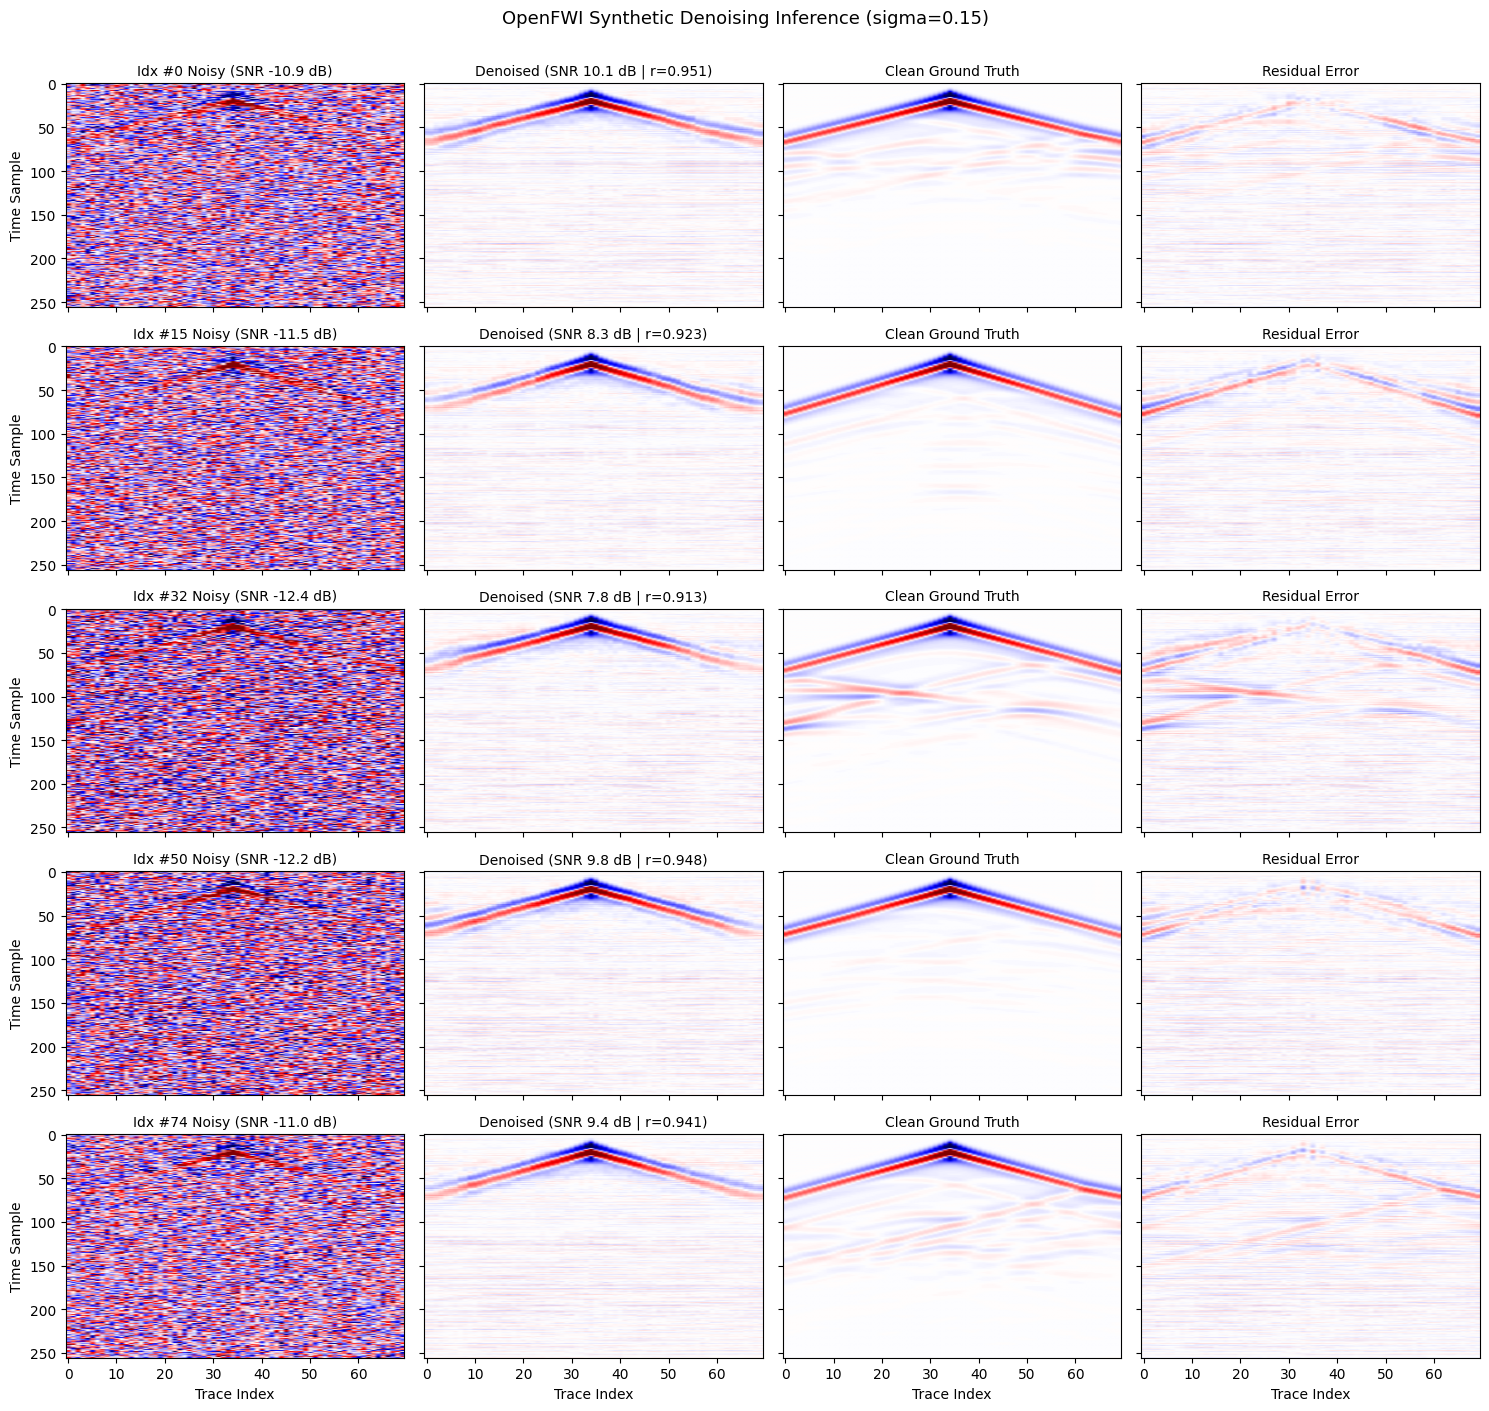

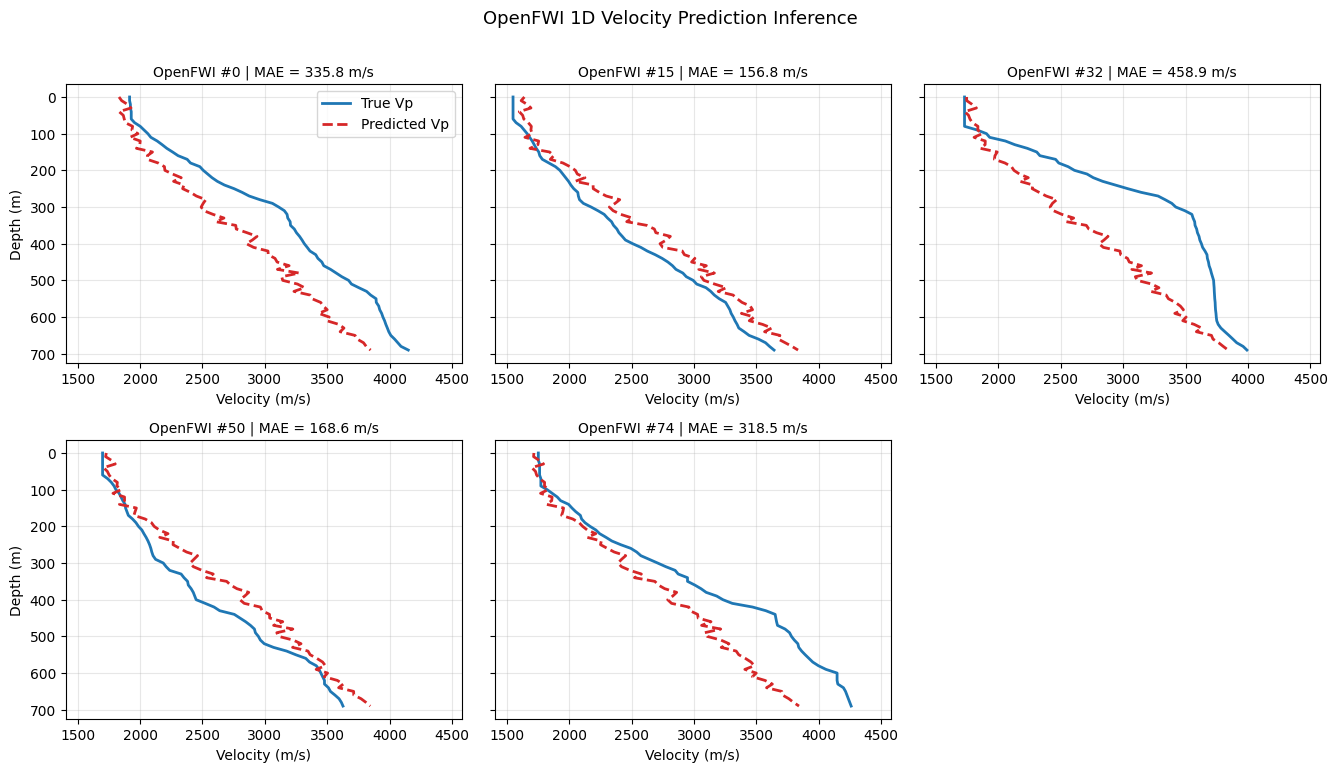

In [19]:
rng_s = np.random.default_rng(SEED)
clean_sel = s_test[SYNTH_EXAMPLE_INDICES]
vel_true_sel = v_test_ms[SYNTH_EXAMPLE_INDICES]
noisy_sel = np.array([
    normalize_gather(g + rng_s.normal(0.0, NOISE_SIGMA, size=g.shape).astype(np.float32))
    for g in clean_sel
], dtype=np.float32)

with torch.no_grad():
    den_sel = model_denoise(torch.tensor(noisy_sel, device=device)).cpu().numpy()
    vel_pred_sel = model_vel(torch.tensor(clean_sel, device=device))[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

print(f"{'Idx':>5} | {'In SNR (dB)':>11} | {'Out SNR (dB)':>12} | {'Pearson r':>9} | {'Vel MAE (m/s)':>13}")
print("-" * 62)
for i, idx in enumerate(SYNTH_EXAMPLE_INDICES):
    s_in = compute_snr_db(clean_sel[i], noisy_sel[i])
    s_out = compute_snr_db(clean_sel[i], den_sel[i])
    r_val = pearson_r(clean_sel[i], den_sel[i])
    mae = float(np.mean(np.abs(vel_pred_sel[i] - vel_true_sel[i])))
    print(f"{idx:5d} | {s_in:11.2f} | {s_out:12.2f} | {r_val:9.4f} | {mae:13.1f}")

# --- Plot 1: OpenFWI Denoising Grid ---
n_s = len(SYNTH_EXAMPLE_INDICES)
fig, axes = plt.subplots(n_s, 4, figsize=(15, 2.8 * n_s), sharex=True, sharey=True)
if n_s == 1:
    axes = axes[None, :]

for row, idx in enumerate(SYNTH_EXAMPLE_INDICES):
    s_in = compute_snr_db(clean_sel[row], noisy_sel[row])
    s_out = compute_snr_db(clean_sel[row], den_sel[row])
    r_val = pearson_r(clean_sel[row], den_sel[row])
    panels = [
        (noisy_sel[row].T, f"Idx #{idx} Noisy (SNR {s_in:.1f} dB)"),
        (den_sel[row].T, f"Denoised (SNR {s_out:.1f} dB | r={r_val:.3f})"),
        (clean_sel[row].T, "Clean Ground Truth"),
        ((clean_sel[row] - den_sel[row]).T, "Residual Error"),
    ]
    for col, (img, ttl) in enumerate(panels):
        axes[row, col].imshow(img, aspect="auto", cmap="seismic", vmin=VMIN, vmax=VMAX)
        axes[row, col].set_title(ttl, fontsize=10)
        if row == n_s - 1:
            axes[row, col].set_xlabel("Trace Index")
    axes[row, 0].set_ylabel("Time Sample")

fig.suptitle(f"OpenFWI Synthetic Denoising Inference (sigma={NOISE_SIGMA})", fontsize=13, y=1.005)
plt.tight_layout()
plt.show()

# --- Plot 2: OpenFWI 1D Velocity Profile Grid ---
ncols = min(3, n_s)
nrows = math.ceil(n_s / ncols)
depth_m = np.arange(VEL_DIM) * 10.0

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.8 * nrows), sharey=True)
axes = np.atleast_1d(axes).ravel()

for i, idx in enumerate(SYNTH_EXAMPLE_INDICES):
    mae = float(np.mean(np.abs(vel_pred_sel[i] - vel_true_sel[i])))
    axes[i].plot(vel_true_sel[i], depth_m, label="True Vp", color="tab:blue", lw=2.0)
    axes[i].plot(vel_pred_sel[i], depth_m, label="Predicted Vp", color="tab:red", ls="--", lw=2.0)
    axes[i].set_title(f"OpenFWI #{idx} | MAE = {mae:.1f} m/s", fontsize=10)
    axes[i].set_xlabel("Velocity (m/s)")
    axes[i].set_xlim(VEL_MIN - 100, VEL_MAX + 100)
    axes[i].grid(alpha=0.3)
    if i % ncols == 0:
        axes[i].set_ylabel("Depth (m)")
    if i == 0:
        axes[i].legend()

axes[0].invert_yaxis()
for j in range(n_s, len(axes)):
    axes[j].axis("off")

fig.suptitle("OpenFWI 1D Velocity Prediction Inference", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 4. USGS Alaska Line 31-81 Field Inference (Denoising, 1D $V_p$ & Zero-Shot Gap Interpolation)

  Win |  Raw-Den r | Removed Energy (%) | 5-Trace Gap SNR (dB)
----------------------------------------------------------------
    0 |     0.6457 |              58.72 |                 5.21
    1 |     0.6278 |              61.03 |                 5.52
    3 |     0.5976 |              64.80 |                 5.00
    5 |     0.5752 |              67.45 |                 4.14
    7 |     0.5448 |              70.72 |                 4.54


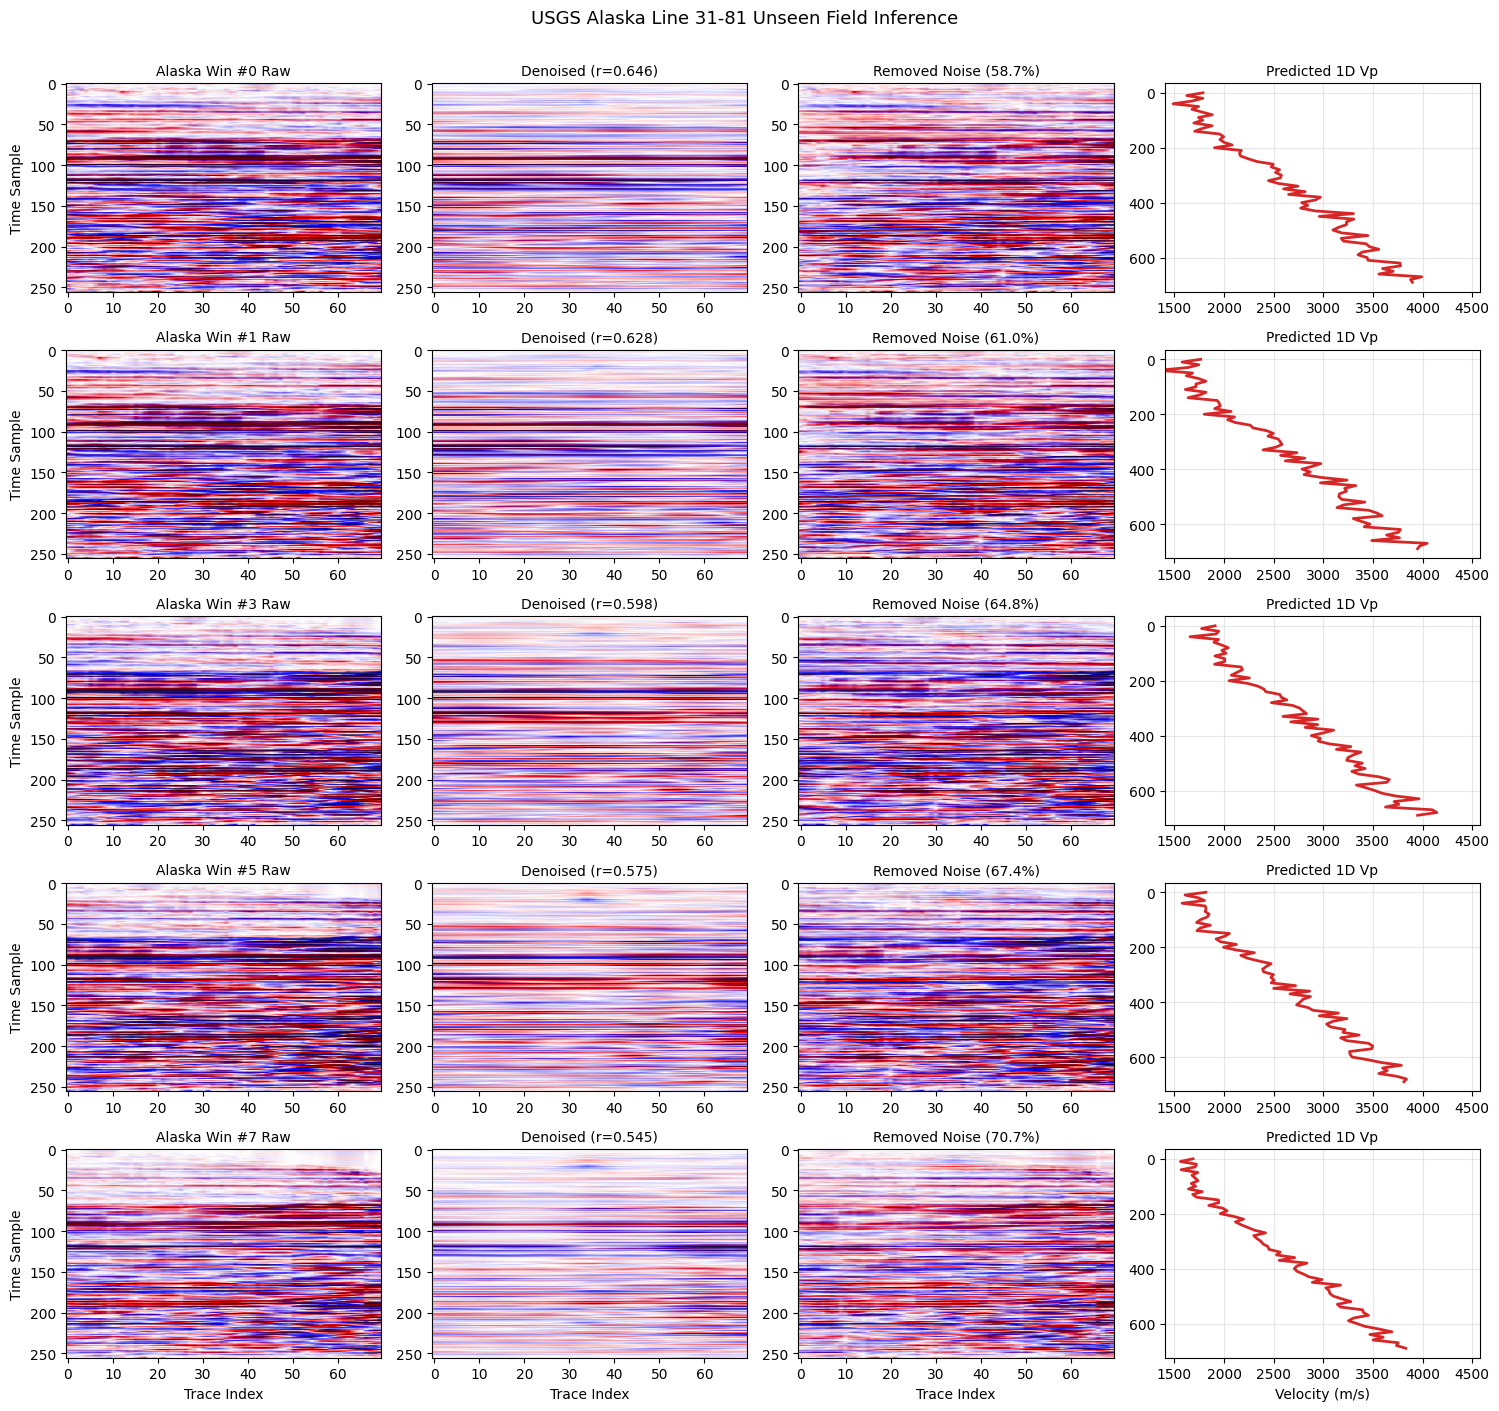

In [20]:
field_sel = f_test[FIELD_EXAMPLE_INDICES]

with torch.no_grad():
    f_tensor = torch.tensor(field_sel, device=device)
    field_den_sel = model_denoise(f_tensor).cpu().numpy()
    field_vel_sel = model_vel(f_tensor)[:, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

field_rem_sel = field_sel - field_den_sel
interp_sel, gap_snrs = [], []
for i, idx in enumerate(FIELD_EXAMPLE_INDICES):
    rec_g, m_gap = zeroshot_gap_interp(model_pretrain, field_sel[i], GAP_START, GAP_END, seed=SEED + idx)
    interp_sel.append(rec_g)
    gap_snrs.append(compute_snr_db(field_sel[i][m_gap], rec_g[m_gap]))

print(f"{'Win':>5} | {'Raw-Den r':>10} | {'Removed Energy (%)':>18} | {'5-Trace Gap SNR (dB)':>20}")
print("-" * 64)
for i, idx in enumerate(FIELD_EXAMPLE_INDICES):
    r_val = pearson_r(field_sel[i], field_den_sel[i])
    rem_pct = float(100.0 * np.sum(field_rem_sel[i] ** 2) / (np.sum(field_sel[i] ** 2) + 1e-12))
    print(f"{idx:5d} | {r_val:10.4f} | {rem_pct:18.2f} | {gap_snrs[i]:20.2f}")

# --- Plot 3: Alaska Field Denoising + 1D Velocity Prediction ---
n_f = len(FIELD_EXAMPLE_INDICES)
depth_m = np.arange(VEL_DIM) * 10.0
fig, axes = plt.subplots(n_f, 4, figsize=(15, 2.8 * n_f))
if n_f == 1:
    axes = axes[None, :]

for row, idx in enumerate(FIELD_EXAMPLE_INDICES):
    r_val = pearson_r(field_sel[row], field_den_sel[row])
    rem_pct = float(100.0 * np.sum(field_rem_sel[row] ** 2) / (np.sum(field_sel[row] ** 2) + 1e-12))

    for col, (img, ttl) in enumerate([
        (field_sel[row].T, f"Alaska Win #{idx} Raw"),
        (field_den_sel[row].T, f"Denoised (r={r_val:.3f})"),
        (field_rem_sel[row].T, f"Removed Noise ({rem_pct:.1f}%)"),
    ]):
        axes[row, col].imshow(img, aspect="auto", cmap="seismic", vmin=VMIN, vmax=VMAX)
        axes[row, col].set_title(ttl, fontsize=10)
        if row == n_f - 1:
            axes[row, col].set_xlabel("Trace Index")
    axes[row, 0].set_ylabel("Time Sample")

    axes[row, 3].plot(field_vel_sel[row], depth_m, color="tab:red", lw=2.0)
    axes[row, 3].invert_yaxis()
    axes[row, 3].set_xlim(VEL_MIN - 100, VEL_MAX + 100)
    axes[row, 3].set_title("Predicted 1D Vp", fontsize=10)
    axes[row, 3].grid(alpha=0.3)
    if row == n_f - 1:
        axes[row, 3].set_xlabel("Velocity (m/s)")

fig.suptitle("USGS Alaska Line 31-81 Unseen Field Inference", fontsize=13, y=1.005)
plt.tight_layout()
plt.show()
